## Описание проекта

**Данные:** сгенерированный датасет, имитирующий B2B-продукт — ГИС-систему для 
энергетики и ритейла. 50 корпоративных клиентов, 2 года работы (2024–2025).

**Что внутри:**
*   `clients` — клиенты: отрасль, регион, дата контракта, ежемесячный платёж.
*   `sessions` — логи использования: дата, длительность сессии, количество модулей.
*   `billing` — платежи: дата, сумма.

**Задачи ноутбука:**
*   Провести RFM-сегментацию клиентов: разделить на активных, растущих и уснувших.
*   Построить когортный анализ: retention по месяцу контракта.
*   Построить кривые выживаемости Каплана-Мейера — дожитие клиентов до оттока.
*   Построить воронку онбординга: контракт → первый вход → регулярное использование.
*   Сформулировать инсайты и рекомендации для бизнеса.

**Инструменты:** Python (pandas, numpy, scipy, lifelines, seaborn).

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from lifelines import KaplanMeierFitter

# Палитра
selected_palette = sns.color_palette("Blues", n_colors=20)

# Загрузка данных (относительный путь)
path = os.path.join('..', 'data', 'raw')

clients = pd.read_csv(os.path.join(path, 'clients.csv'))
sessions = pd.read_csv(os.path.join(path, 'sessions.csv'))
billing = pd.read_csv(os.path.join(path, 'billing.csv'))

print(f"Клиентов: {clients.shape[0]}")
print(f"Сессий: {sessions.shape[0]}")
print(f"Платежей: {billing.shape[0]}")

Клиентов: 50
Сессий: 3225
Платежей: 466


# 2. RFM-сегментация клиентов

#### Рассчитываем Recency, Frequency, Monetary для каждого клиента.

In [49]:
# Точка отсчёта — конец периода
NOW = pd.Timestamp('2025-12-31')

# Recency: дней с последней сессии
recency = sessions.groupby('client_id')['session_date'].max().reset_index()
recency['Recency'] = (NOW - pd.to_datetime(recency['session_date'])).dt.days
recency = recency[['client_id', 'Recency']]

# Frequency: среднее количество сессий в месяц
first_session = sessions.groupby('client_id')['session_date'].min().reset_index()
first_session.columns = ['client_id', 'first_session_date']

client_months = first_session.copy()
client_months['months_active'] = (
    (NOW - pd.to_datetime(client_months['first_session_date'])).dt.days / 30
).round(0).clip(lower=1)

total_sessions = sessions.groupby('client_id').size().reset_index(name='total_sessions')
frequency = total_sessions.merge(client_months, on='client_id')
frequency['Frequency'] = (frequency['total_sessions'] / frequency['months_active']).round(1)
frequency = frequency[['client_id', 'Frequency']]

# Monetary: среднемесячный платёж
monetary = billing.groupby('client_id')['amount'].mean().reset_index()
monetary.columns = ['client_id', 'Monetary']

# Объединяем
rfm = recency.merge(frequency, on='client_id', how='left') \
             .merge(monetary, on='client_id', how='left')

# Добавляем информацию о клиентах
rfm = rfm.merge(clients, on='client_id', how='left')

# Заполняем пропуски: клиенты без сессий
rfm['Recency'] = rfm['Recency'].fillna(365)
rfm['Frequency'] = rfm['Frequency'].fillna(0)
rfm['Monetary'] = rfm['Monetary'].fillna(0)

print(f"RFM-таблица: {rfm.shape}")
rfm.head()

RFM-таблица: (47, 8)


,client_id,Recency,Frequency,Monetary,industry,region,contract_date,monthly_fee
0,C001,136,5.8,117848.693191,Верфи,СПб,2025-02-22,120000
1,C002,30,7.2,49388.117343,Сетевая компания,СПб,2024-10-15,50000
2,C003,179,4.8,246130.940991,Нефтегаз,Москва,2025-01-13,250000
3,C004,213,1.4,53192.305768,Сетевая компания,СПб,2025-05-04,50000
4,C005,425,1.7,116218.205877,Сетевая компания,Юг,2024-08-18,120000


In [50]:
# Делим на терцили (три равные группы) и присваиваем баллы 1-3
rfm['R_score'] = pd.qcut(rfm['Recency'], q=3, labels=[3, 2, 1])  # меньше дней → выше балл
rfm['F_score'] = pd.qcut(rfm['Frequency'], q=3, labels=[1, 2, 3])  # больше сессий → выше балл
rfm['M_score'] = pd.qcut(rfm['Monetary'], q=3, labels=[1, 2, 3])  # больше платежей → выше балл

# Сумма баллов
rfm['RFM_total'] = rfm['R_score'].astype(int) + rfm['F_score'].astype(int) + rfm['M_score'].astype(int)

# Сегменты
def get_segment(total):
    if total >= 7:
        return 'Активный'
    elif total >= 5:
        return 'Растущий'
    else:
        return 'Уснувший'

rfm['Segment'] = rfm['RFM_total'].apply(get_segment)

# Результат
print(rfm['Segment'].value_counts())
rfm[['client_id', 'Recency', 'Frequency', 'Monetary', 'R_score', 'F_score', 'M_score', 'RFM_total', 'Segment']].head(10)

Segment
Активный    23
Уснувший    13
Растущий    11
Name: count, dtype: int64


,client_id,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_total,Segment
0,C001,136,5.8,117848.693191,2,2,2,6,Растущий
1,C002,30,7.2,49388.117343,3,3,1,7,Активный
2,C003,179,4.8,246130.940991,2,2,3,7,Активный
3,C004,213,1.4,53192.305768,2,1,1,4,Уснувший
4,C005,425,1.7,116218.205877,1,1,2,4,Уснувший
5,C006,334,4.0,78975.941529,1,2,1,4,Уснувший
6,C007,19,8.8,178612.287611,3,3,3,9,Активный
7,C008,328,3.8,120572.309805,1,2,2,5,Растущий
8,C009,266,2.6,48781.281895,1,1,1,3,Уснувший
9,C010,436,3.0,178547.725750,1,1,3,5,Растущий


**RFM-сегментация:**
*   Активных: 23 клиента — регулярно пользуются, приносят доход.
*   Растущих: 11 клиентов — средняя активность, есть потенциал для роста.
*   Уснувших: 13 клиентов — почти каждый четвёртый. Платят, но не пользуются продуктом.
*   Уснувшие — прямой резерв для роста. Если их реанимировать, вырастет и удержание, и возможность допродаж.

# 3. Когортный анализ retention

#### Смотрим, какой процент клиентов остаётся активным через N месяцев после контракта.

In [51]:
# Определяем когорту — месяц контракта
clients['cohort_month'] = pd.to_datetime(clients['contract_date']).dt.to_period('M')

# Все месяцы активности
sessions['session_month'] = pd.to_datetime(sessions['session_date']).dt.to_period('M')

# Для каждого клиента находим месяц последней сессии
last_session_month = sessions.groupby('client_id')['session_month'].max().reset_index()
last_session_month.columns = ['client_id', 'last_month']

# Объединяем с клиентами
cohorts = clients.merge(last_session_month, on='client_id', how='left')

# Считаем, сколько месяцев клиент был активен
cohorts['months_active'] = (
    (cohorts['last_month'] - cohorts['cohort_month']).apply(lambda x: x.n if pd.notna(x) else 0)
)

# Строим таблицу удержания: для каждой когорты — сколько клиентов активно через 0, 1, 2... месяцев
cohort_counts = cohorts.groupby('cohort_month').size()
cohort_data = []

for cohort_month in sorted(cohorts['cohort_month'].unique()):
    cohort_clients = cohorts[cohorts['cohort_month'] == cohort_month]
    total = len(cohort_clients)
    row = [str(cohort_month), total]
    for month in range(0, 12):
        active = (cohort_clients['months_active'] >= month).sum()
        row.append(active)
    cohort_data.append(row)

# Таблица когорт
months_cols = [f'M{month:02d}' for month in range(0, 12)]
cohort_table = pd.DataFrame(cohort_data, columns=['Когорта', 'Клиентов'] + months_cols).set_index('Когорта')

# В процентах
cohort_pct = cohort_table.div(cohort_table['Клиентов'], axis=0) * 100
cohort_pct = cohort_pct.drop(columns=['Клиентов']).round(1)

cohort_pct

,M00,M01,M02,M03,M04,M05,M06,M07,M08,M09,M10,M11
Когорта,,,,,,,,,,,,
2024-01,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,75.0,75.0
2024-02,100.0,75.0,75.0,75.0,75.0,75.0,75.0,50.0,50.0,25.0,25.0,25.0
2024-03,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0,0.0,0.0
2024-04,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2024-05,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0
2024-06,100.0,100.0,100.0,100.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0
2024-07,100.0,100.0,100.0,100.0,100.0,100.0,66.7,66.7,66.7,66.7,0.0,0.0
2024-08,100.0,85.7,85.7,71.4,71.4,71.4,71.4,57.1,57.1,57.1,57.1,57.1
2024-09,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


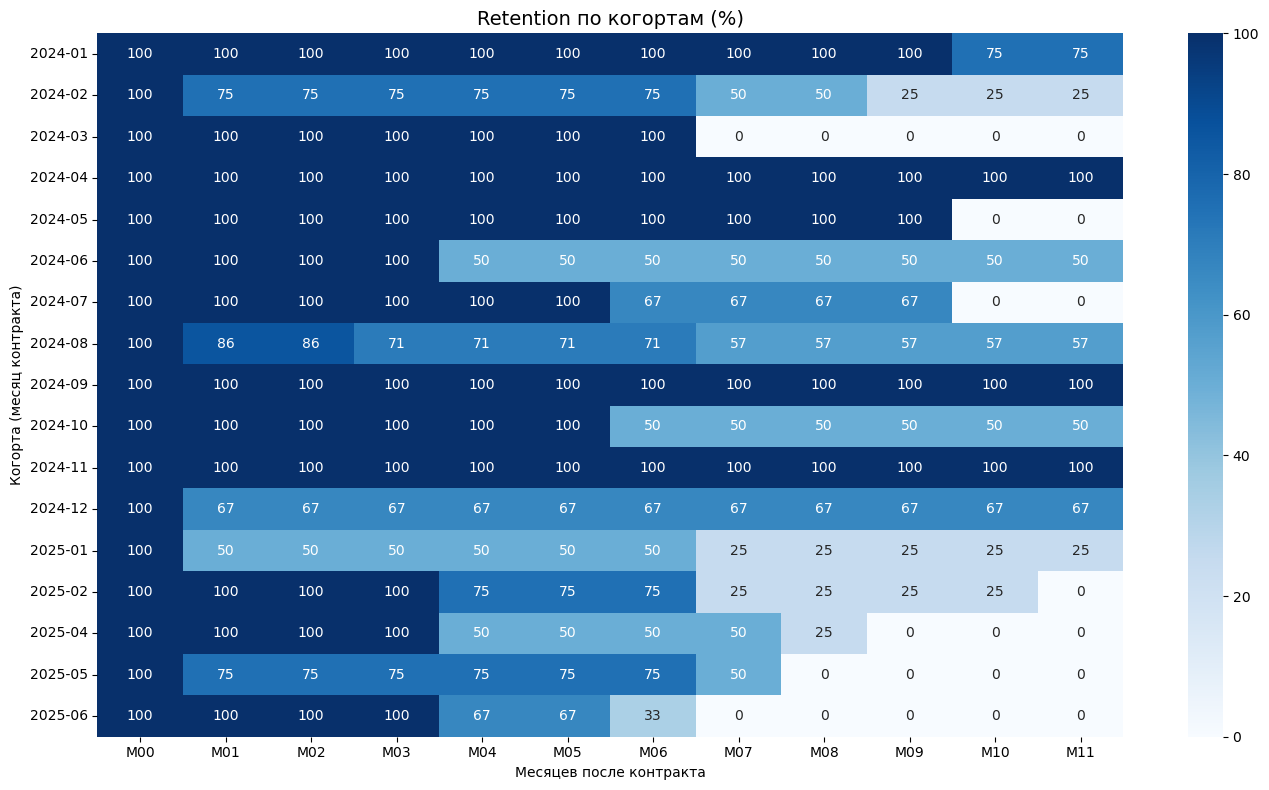

In [54]:
# Тепловая карта retention
plt.figure(figsize=(14, 8))
sns.heatmap(cohort_pct, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, center=50)
plt.title('Retention по когортам (%)', fontsize=14)
plt.ylabel('Когорта (месяц контракта)')
plt.xlabel('Месяцев после контракта')
plt.tight_layout()
plt.show()

**Когортный анализ:**
*   Разброс retention между когортами очень высокий: от 0% до 100%.
*   Хорошие когорты: 2024-04, 2024-09, 2024-11 — 100% retention на всём протяжении.
*   Плохие когорты: 2024-03 (0% с M07), 2025-01 (25% с M07), 2025-06 (0% с M07).
*   Критический период — первые 3–6 месяцев. Именно здесь происходит большинство оттоков.
*   Разброс между когортами может говорить о нестабильном процессе онбординга — 
    где-то клиентов довели до результата, где-то бросили после контракта.

# 4. Кривые выживаемости Каплана-Мейера

#### Оцениваем дожитие клиентов до оттока. Событие = клиент перестал пользоваться продуктом.

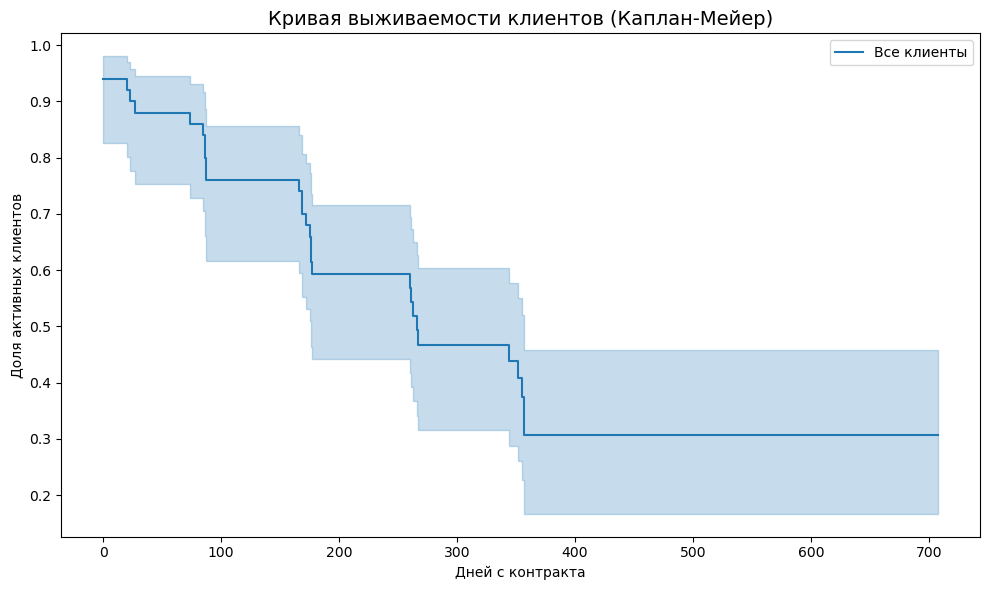

In [55]:
# Определяем событие «отток»: клиент неактивен последние 90 дней периода
NOW = pd.Timestamp('2025-12-31')

# Для каждого клиента: дата последней сессии и дата первой сессии
last_session = sessions.groupby('client_id')['session_date'].max().reset_index()
last_session.columns = ['client_id', 'last_session_date']
first_session = sessions.groupby('client_id')['session_date'].min().reset_index()
first_session.columns = ['client_id', 'first_session_date']

# Объединяем с клиентами
km_data = clients.merge(last_session, on='client_id', how='left') \
                 .merge(first_session, on='client_id', how='left')

# Дата оттока: последняя сессия (если была), иначе дата контракта
km_data['last_date'] = km_data['last_session_date'].fillna(km_data['contract_date'])
km_data['last_date'] = pd.to_datetime(km_data['last_date'], format='mixed')

# Событие: отток, если последняя сессия была более 90 дней назад от конца периода
km_data['churned'] = ((NOW - km_data['last_date']).dt.days > 90).astype(int)

# Время жизни: от контракта до последней активности (или до NOW, если активен)
km_data['lifetime_days'] = (
    (km_data['last_date'] - pd.to_datetime(km_data['contract_date'])).dt.days
)

# Строим кривые
kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

# Общая кривая
kmf.fit(durations=km_data['lifetime_days'], event_observed=km_data['churned'], label='Все клиенты')
kmf.plot_survival_function()

plt.title('Кривая выживаемости клиентов (Каплан-Мейер)', fontsize=14)
plt.xlabel('Дней с контракта')
plt.ylabel('Доля активных клиентов')
plt.legend()
plt.tight_layout()
plt.show()

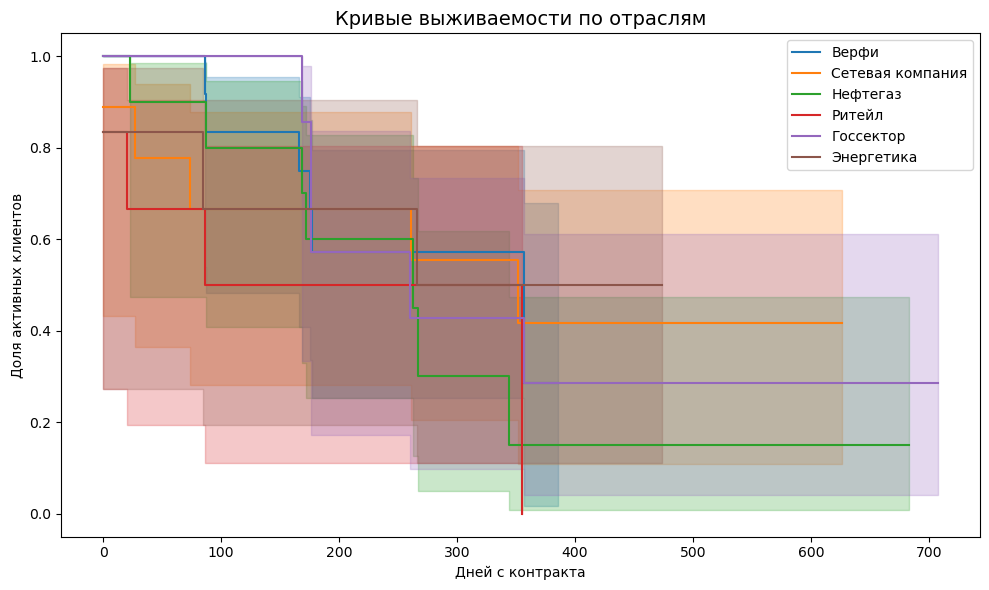

In [56]:
# Кривые по отраслям
plt.figure(figsize=(10, 6))

for industry in km_data['industry'].unique():
    mask = km_data['industry'] == industry
    if mask.sum() > 1:
        kmf.fit(
            durations=km_data[mask]['lifetime_days'], 
            event_observed=km_data[mask]['churned'], 
            label=industry
        )
        kmf.plot_survival_function()

plt.title('Кривые выживаемости по отраслям', fontsize=14)
plt.xlabel('Дней с контракта')
plt.ylabel('Доля активных клиентов')
plt.legend()
plt.tight_layout()
plt.show()

In [57]:
# Выживаемость в числах — ключевые точки
print("=== Выживаемость клиентов (Каплан-Мейер) ===")
print(f"Медианное время жизни: {kmf.median_survival_time_:.0f} дней")

print("\nДоля активных через:")
for days in [90, 180, 270, 365, 540, 720]:
    surv = kmf.survival_function_at_times(days).values[0]
    print(f"  {days} дней ({days//30} мес): {surv:.0%}")

print(f"\nВсего клиентов: {len(km_data)}")
print(f"Из них отток: {km_data['churned'].sum()}")
print(f"Доля оттока: {km_data['churned'].mean():.0%}")

# По отраслям
print("\n=== Выживаемость по отраслям (через 365 дней) ===")
for industry in km_data['industry'].unique():
    mask = km_data['industry'] == industry
    if mask.sum() > 1:
        kmf_industry = KaplanMeierFitter()
        kmf_industry.fit(
            durations=km_data[mask]['lifetime_days'], 
            event_observed=km_data[mask]['churned']
        )
        surv_365 = kmf_industry.survival_function_at_times(365).values[0]
        print(f"  {industry}: {surv_365:.0%} ({mask.sum()} клиентов)")

=== Выживаемость клиентов (Каплан-Мейер) ===
Медианное время жизни: inf дней

Доля активных через:
  90 дней (3 мес): 67%
  180 дней (6 мес): 67%
  270 дней (9 мес): 50%
  365 дней (12 мес): 50%
  540 дней (18 мес): 50%
  720 дней (24 мес): 50%

Всего клиентов: 50
Из них отток: 30
Доля оттока: 60%

=== Выживаемость по отраслям (через 365 дней) ===
  Верфи: 29% (12 клиентов)
  Сетевая компания: 42% (9 клиентов)
  Нефтегаз: 15% (10 клиентов)
  Ритейл: 0% (6 клиентов)
  Госсектор: 29% (7 клиентов)
  Энергетика: 50% (6 клиентов)


**Кривые выживаемости:**

*   Медианное время жизни — не достигнуто.
*   Основной отток происходит в первые 3–9 месяцев: к 3-му месяцу остаётся 67%, к 9-му — 50%, дальше стабильно.
*   Всего отток — 60% (30 из 50 клиентов). Половина клиентов уходит в первый год.

**По отраслям:**
*   **Энергетика** — лучшая выживаемость (50% через год).
*   **Сетевая компания** — 42% — неплохо.
*   **Ритейл** — 0% через год. Все клиенты ушли. Критическая зона — нужно разбираться.
*   **Нефтегаз** — 15% — очень низкая выживаемость.
*   **Верфи и Госсектор** — 29% — ниже среднего.

**Вывод:** продукт лучше всего приживается в Энергетике и Сетевых компаниях. Ритейл и Нефтегаз требуют срочного внимания — возможно, продукт не закрывает их потребности или нужен другой подход к онбордингу.

# 5. Воронка онбординга

#### Строим воронку: сколько клиентов доходит от контракта до регулярного использования.

In [58]:
# Этапы воронки:
# 1. Контракт — все клиенты
# 2. Первый вход — хотя бы одна сессия
# 3. Загрузка данных — 3+ сессии (имитация настройки)
# 4. Регулярное использование — 5+ сессий в месяц

total_clients = len(clients)

# Клиенты с хотя бы одной сессией
clients_with_session = sessions['client_id'].nunique()

# Клиенты с 3+ сессиями всего (имитация загрузки данных)
clients_3plus = sessions.groupby('client_id').filter(lambda x: len(x) >= 3)['client_id'].nunique()

# Клиенты с регулярным использованием (5+ сессий в месяц в среднем)
monthly_sessions = sessions.groupby('client_id').size()
client_lifespan = sessions.groupby('client_id')['session_date'].apply(
    lambda x: max(1, (pd.to_datetime(x.max()) - pd.to_datetime(x.min())).days / 30)
)
monthly_avg = monthly_sessions / client_lifespan
clients_regular = (monthly_avg >= 5).sum()

# Строим воронку
funnel_stages = ['Контракт', 'Первый вход', 'Настройка (3+ сессии)', 'Регулярное использование']
funnel_values = [total_clients, clients_with_session, clients_3plus, clients_regular]

# Воронка step-by-step
print("=== Воронка онбординга ===")
prev = funnel_values[0]
for stage, value in zip(funnel_stages, funnel_values):
    conv = value / prev * 100 if prev > 0 else 0
    print(f"{stage}: {value} клиентов (конверсия: {conv:.0f}%)")
    prev = value

print(f"\nОбщая конверсия: {funnel_values[-1] / funnel_values[0] * 100:.0f}%")

=== Воронка онбординга ===
Контракт: 50 клиентов (конверсия: 100%)
Первый вход: 47 клиентов (конверсия: 94%)
Настройка (3+ сессии): 47 клиентов (конверсия: 100%)
Регулярное использование: 44 клиентов (конверсия: 94%)

Общая конверсия: 88%


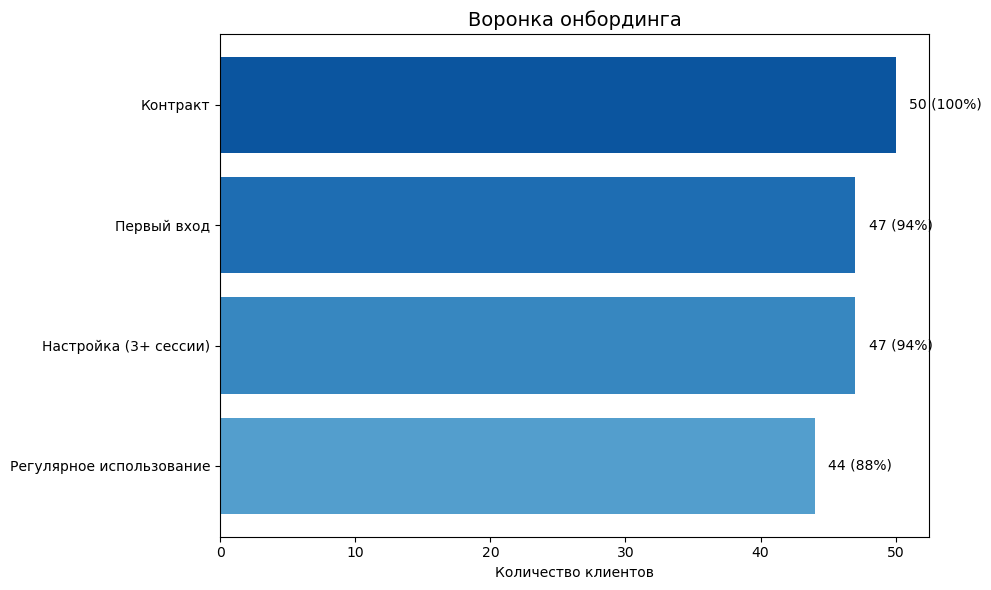

In [59]:
# Визуализация воронки
plt.figure(figsize=(10, 6))
colors = [selected_palette[17], selected_palette[15], selected_palette[13], selected_palette[11]]
bars = plt.barh(funnel_stages, funnel_values, color=colors)
plt.title('Воронка онбординга', fontsize=14)
plt.xlabel('Количество клиентов')
plt.gca().invert_yaxis()

# Подписи
for bar, value in zip(bars, funnel_values):
    plt.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
             f'{value} ({value/total_clients*100:.0f}%)', va='center')

plt.tight_layout()
plt.show()

**Воронка онбординга:**
*   Контракт → Первый вход: 94% (3 клиента не зашли ни разу).
*   Первый вход → Настройка (3+ сессии): 100% — те, кто зашёл, проходят настройку.
*   Настройка → Регулярное использование: 94% (3 клиента не доходят до регулярного использования).
*   **Общая конверсия: 88%** — 6 из 50 клиентов теряются на старте.
*   **Узкое место:** самый первый шаг — 3 клиента вообще не начали пользоваться продуктом после контракта.
    Стоит проверить причины: возможно, не назначен ответственный, не прошло обучение, или продукт не соответствует ожиданиям.
    

# 6. Воронка полного цикла (дожитие)

#### Две воронки: относительная (от первого шага) и step-by-step (между соседними).

In [80]:
# Этапы полного цикла
regular = clients_regular
active_6m = (km_data['lifetime_days'] >= 180).sum()
active_12m = (km_data['lifetime_days'] >= 365).sum()

stages = ['Регулярное использование', 'Активны 6+ мес', 'Активны 12+ мес']
values = [regular, active_6m, active_12m]

# Относительная воронка
print("=== Относительная воронка (от первого шага) ===")
base = values[0]
for stage, value in zip(stages, values):
    print(f"{stage}: {value} клиентов ({value / base * 100:.0f}%)")

# Step-by-step
print("\n=== Step-by-step (конверсия между этапами) ===")
prev = values[0]
for stage, value in zip(stages, values):
    conv = value / prev * 100 if prev > 0 else 0
    print(f"{stage}: {value} клиентов (конверсия: {conv:.0f}%)")
    prev = value


=== Относительная воронка (от первого шага) ===
Регулярное использование: 44 клиентов (100%)
Активны 6+ мес: 27 клиентов (61%)
Активны 12+ мес: 9 клиентов (20%)

=== Step-by-step (конверсия между этапами) ===
Регулярное использование: 44 клиентов (конверсия: 100%)
Активны 6+ мес: 27 клиентов (конверсия: 61%)
Активны 12+ мес: 9 клиентов (конверсия: 33%)


**Воронка полного цикла:**

*   Из 44 клиентов, дошедших до регулярного использования, через 6 месяцев активны 61%, через 12 месяцев — 20%. Главная просадка — первые полгода.
*   13 клиентов из 47 — At-Risk (28%). Они платят, но не пользуются продуктом. Формально живы, но находятся под угрозой оттока.
*   Step-by-step показывает, что критический перелом — между 6 и 12 месяцами (конверсия падает с 61% до 33%). Именно здесь клиенты превращаются в At-Risk или уходят.
*   Рекомендация: отслеживать активность в первые 6 месяцев. Если клиент не набрал темп — proactive outreach, не ждать года.

# 7. At-Risk клиенты: платят, но не пользуются

#### Находим клиентов, которые продолжают платить, но перестали пользоваться продуктом.

In [76]:
# At-Risk — уснувшие клиенты, которые продолжают платить
at_risk_clients = rfm[(rfm['Segment'] == 'Уснувший') & (rfm['Monetary'] > 0)]

print(f"=== At-Risk клиенты ===")
print(f"Всего уснувших: {len(rfm[rfm['Segment'] == 'Уснувший'])}")
print(f"Из них платят (at-risk): {len(at_risk_clients)}")
print(f"Доля at-risk от всей базы: {len(at_risk_clients) / len(rfm) * 100:.0f}%")
print(f"Они приносят в месяц: {at_risk_clients['Monetary'].sum():,.0f} ₽")
print(f"\nОтрасли at-risk клиентов:")
print(at_risk_clients['industry'].value_counts())

=== At-Risk клиенты ===
Всего уснувших: 13
Из них платят (at-risk): 13
Доля at-risk от всей базы: 28%
Они приносят в месяц: 1,022,669 ₽

Отрасли at-risk клиентов:
industry
Верфи               4
Нефтегаз            3
Госсектор           3
Сетевая компания    2
Ритейл              1
Name: count, dtype: int64


In [78]:
from datetime import timedelta
# Проверяем гипотезу: низкая активность в первые 3 месяца → at-risk
first_3m_sessions = []
for _, client in clients.iterrows():
    contract_start = pd.to_datetime(client['contract_date'])
    mask = (sessions['client_id'] == client['client_id']) & \
           (pd.to_datetime(sessions['session_date']) >= contract_start) & \
           (pd.to_datetime(sessions['session_date']) < contract_start + timedelta(days=90))
    session_count = mask.sum()
    first_3m_sessions.append({
        'client_id': client['client_id'],
        'sessions_first_3m': session_count
    })

first_3m_df = pd.DataFrame(first_3m_sessions)

# Объединяем с RFM
rfm_with_activity = rfm.merge(first_3m_df, on='client_id', how='left')
rfm_with_activity['sessions_first_3m'] = rfm_with_activity['sessions_first_3m'].fillna(0)

# Сравниваем: высокая vs низкая активность
rfm_with_activity['high_activity'] = rfm_with_activity['sessions_first_3m'] >= 10
rfm_with_activity['is_at_risk'] = (rfm_with_activity['Segment'] == 'Уснувший') & (rfm_with_activity['Monetary'] > 0)

high = rfm_with_activity[rfm_with_activity['high_activity']]
low = rfm_with_activity[~rfm_with_activity['high_activity']]

print(f"\n=== Гипотеза: активность в первые 3 месяца → at-risk ===")
print(f"С высокой активностью (≥10 сессий): {len(high)} клиентов")
print(f"  Из них at-risk: {high['is_at_risk'].sum()} ({high['is_at_risk'].mean():.0%})")
print(f"С низкой активностью (<10 сессий): {len(low)} клиентов")
print(f"  Из них at-risk: {low['is_at_risk'].sum()} ({low['is_at_risk'].mean():.0%})")


=== Гипотеза: активность в первые 3 месяца → at-risk ===
С высокой активностью (≥10 сессий): 41 клиентов
  Из них at-risk: 11 (27%)
С низкой активностью (<10 сессий): 6 клиентов
  Из них at-risk: 2 (33%)


**At-Risk клиенты:**

*   13 клиентов из 47 — at-risk (28%). Платят, но не пользуются продуктом.
*   Они приносят 1 022 669 ₽ в месяц — это деньги, которые висят на волоске.
*   Основные отрасли at-risk: Верфи (4), Нефтегаз (3), Госсектор (3).

**Гипотеза: активность в первые 3 месяца → at-risk**

*   С низкой активностью (<10 сессий): 2 из 6 стали at-risk (33%).
*   С высокой активностью (≥10 сессий): 11 из 41 стали at-risk (27%).
*   Разница есть, но на маленькой выборке не драматична. 
*   **Вывод:** низкая активность в первые 3 месяца — потенциальный сигнал, но не единственный фактор. 
    Стоит комбинировать с другими признаками: отрасль, регион, частота платежей.

### 6. Ключевые инсайты и рекомендации

### RFM-сегментация

**Что увидели:** Из 50 клиентов — 23 активных, 11 растущих, 13 уснувших. Почти каждый четвёртый клиент — «уснувший».

**Инсайт:** 13 уснувших клиентов — это прямой резерв для роста. Они уже платят, но не пользуются продуктом. Если их реанимировать — вырастет и удержание, и возможность допродаж.

**Рекомендация:** Провести точечный обзвон уснувших клиентов с предложением аудита и перенастройки. 

## Когортный анализ и кривые выживаемости

**Что увидели:** Основной отток происходит в первые 3–9 месяцев. К 9-му месяцу остаётся 50% клиентов, дальше стабильно. Всего отток — 60% (30 из 50 клиентов).

**Инсайт:** Каждый второй клиент уходит в первый год. Самый критический период — первые полгода.

**По отраслям:** Энергетика (50%) и Сетевые компании (42%) — лучшие. Ритейл (0%) и Нефтегаз (15%) — зона риска.

**Рекомендация:** Усилить онбординг и поддержку в первые 3 месяца. Для Ритейла и Нефтегаза — провести отдельное исследование причин оттока.

---

### Воронка онбординга

**Что увидели:** Общая конверсия — 88%. 6 клиентов из 50 теряются: 3 не зашли ни разу, 3 не дошли до регулярного использования.

**Инсайт:** Проблема не в продукте, а в процессе запуска. Клиенты подписали контракт, но не начали пользоваться.

**Рекомендация:** Ввести контрольную точку через 2 недели после контракта. Если нет первого входа — менеджер выходит на клиента. Не ждать месяц.

---

### Воронка полного цикла и At-Risk клиенты

**Что увидели:** Из 44 клиентов, дошедших до регулярного использования, через 12 месяцев активны только 20%. 13 клиентов из 47 — at-risk (28%): платят, но не пользуются.

**Инсайт:** Основная просадка — между 6 и 12 месяцами. Клиенты, которые не набрали темп в первые полгода, с высокой вероятностью становятся at-risk или уходят.

**Рекомендация:** Отслеживать активность в первые 3–6 месяцев. Если клиент не достигает целевых метрик — proactive outreach, не ждать продления.

---

### Итог: что делать бизнесу

1. **Онбординг — приоритет №1.** Контрольная точка через 2 недели. Не ждать оттока.
2. **Удержание — приоритет №2.** Самый критический период — первые 6 месяцев. Усилить поддержку в это время.
3. **Отраслевой фокус.** Энергетика и Сетевые компании — тиражировать успешный опыт. Ритейл, Нефтегаз, Госсектор и Верфи — разобраться и адаптировать подход.
4. **RFM-мониторинг.** Обновлять ежемесячно, выявлять уснувших и at-risk до того, как они уйдут.



## 7. Дашборд

Интерактивный дашборд в Yandex DataLens: [Product Health Dashboard](https://datalens.ru/pbgqn3y67rn48-produktovaya-analitika-retention-i-ottok)

На дашборде:
*   RFM-сегментация клиентов
*   Воронка онбординга
*   Ключевые метрики

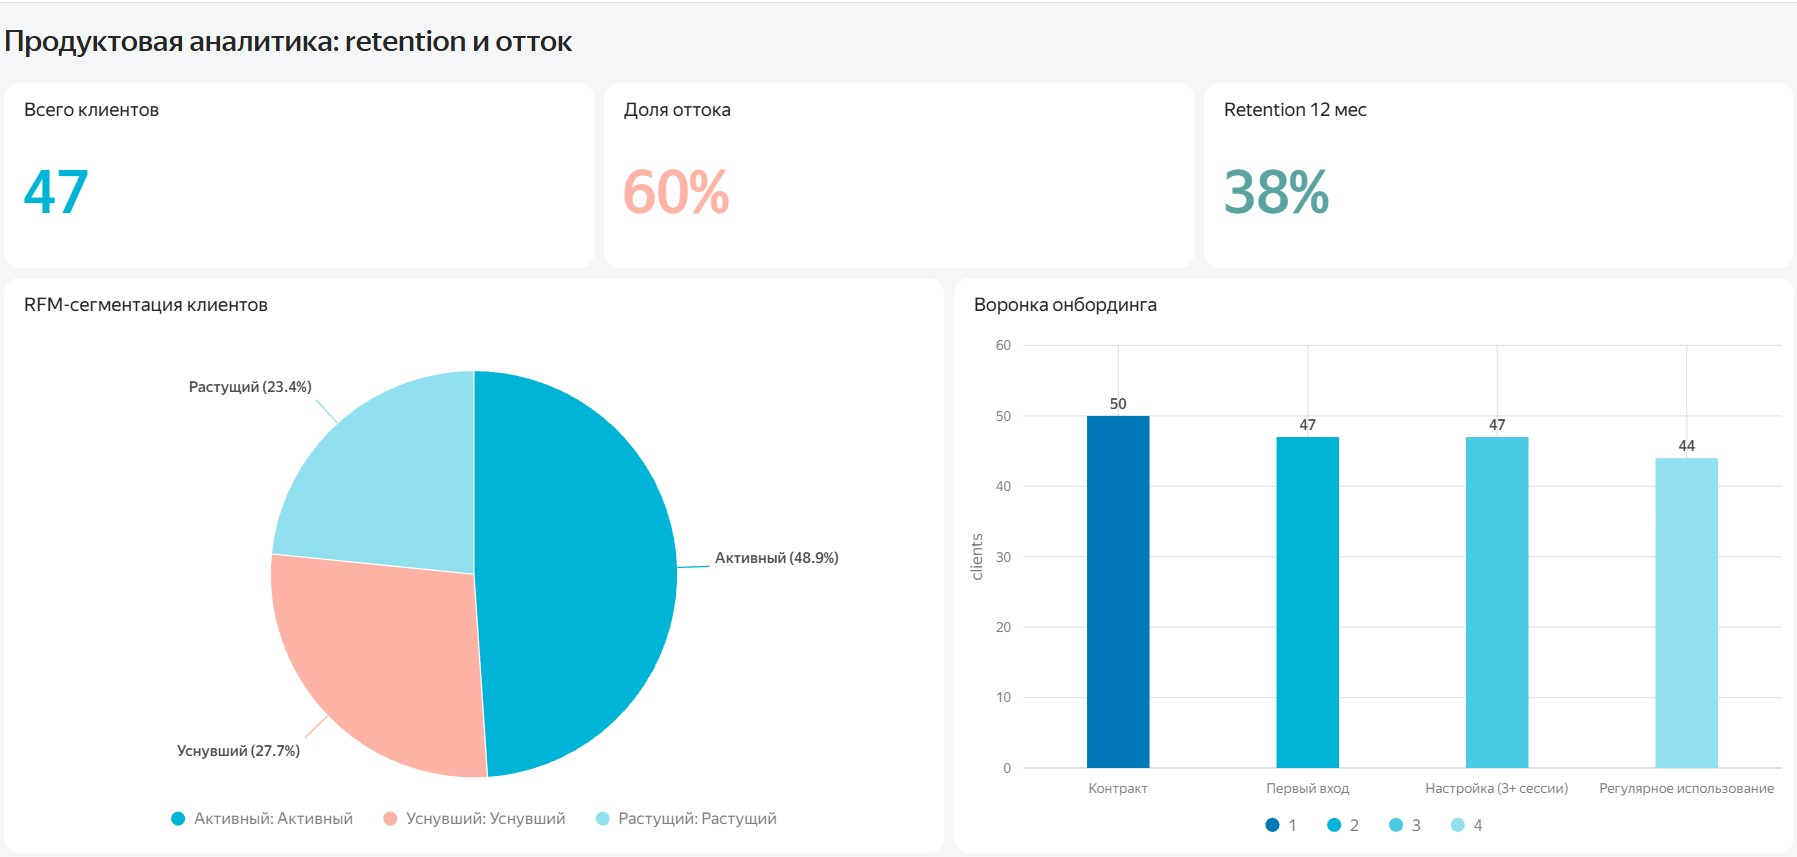